# Q2 – Notebook 2 of 3: Baseline BiGRU + Additive Attention (training and evaluation)
**DSL 504 – NLP Group Assignment 2 · Question 2**

This notebook implements the baseline **without Transformers**: pre-trained fastText embeddings (frozen for the first epoch, then unfrozen) → 2-layer bidirectional GRU → additive attention pooling → dropout → linear layer (5 classes). It trains the model with two seeds (42, 43), plots the training/validation curves, evaluates on the test set (once per model) and saves everything needed by notebook 3.

**Needs:** the output of notebook 1 (`prep/` on Drive). **Produces:** checkpoints, training histories, test predictions, `baseline_info.json`, `baseline_curves.png`, `baseline_confusion.png`.

**About the training cells:** section 4a runs a *live* one-epoch training of the baseline so that the training loop and its output are visible in this notebook (it is a demonstration, nothing is saved from it). Section 4b trains the two real runs; a run is **skipped if its checkpoint and history file already exist** on Drive, and section 4c prints the full per-epoch training log of every run from the saved histories.

In [1]:
import os
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
import random, time, json, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt, seaborn as sns

try:
    from google.colab import drive
    drive.mount('/content/drive')
    CKPT_DIR = '/content/drive/MyDrive/GROUP_ASSIGNMENT_2/Q2_final'
except ImportError:
    CKPT_DIR = './Q2_final'
PREP_DIR = f'{CKPT_DIR}/prep'            # artifacts written by notebook 1
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(PREP_DIR, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '| torch', torch.__version__)
assert device.type == 'cuda', 'Select a GPU runtime: Runtime > Change runtime type > GPU'
assert os.path.exists(f'{PREP_DIR}/classic.npz'), 'Run notebook 1 (preprocessing) first.'

Mounted at /content/drive
device: cuda | torch 2.11.0+cu130


## 0. Configuration
`FORCE_RETRAIN = False` reuses finished runs; `RUN_DEMO = True` runs the one-epoch live demonstration (about 2 minutes) so that a training log is visible.

In [2]:
FORCE_RETRAIN = False
RUN_DEMO = True
SEEDS = [42, 43]
HID, EMB_DIM = 128, 300
RNN_BS, RNN_LR, RNN_MAX_EPOCHS, RNN_PATIENCE, CLIP = 128, 1e-3, 10, 3, 1.0
TOL = 0.003                  # allowed gap between logged and re-computed validation macro-F1
PAD, UNK = 0, 1
COLS = ['epoch', 'train_loss', 'train_f1', 'val_loss', 'val_acc', 'val_f1']

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
def ckpt_path(s): return f'{CKPT_DIR}/baseline_seed{s}.pt'
def hist_path(s): return f'{CKPT_DIR}/baseline_seed{s}_history.json'
def todo(s): return FORCE_RETRAIN or not (os.path.exists(ckpt_path(s)) and os.path.exists(hist_path(s)))
print({f'baseline_s{s}': ('train' if todo(s) else 'reuse') for s in SEEDS})

{'baseline_s42': 'reuse', 'baseline_s43': 'reuse'}


## 1. Load the preprocessed data (from notebook 1)

In [3]:
Z = np.load(f'{PREP_DIR}/classic.npz')
Xtr, Xva, Xte, ytr, yva, yte = (Z[k] for k in ('Xtr', 'Xva', 'Xte', 'ytr', 'yva', 'yte'))
itos = json.load(open(f'{PREP_DIR}/vocab.json'))
FT = json.load(open(f'{CKPT_DIR}/emb_meta.json'))
emb_matrix = torch.tensor(np.load(f'{CKPT_DIR}/emb_matrix.npy'))
assert emb_matrix.shape[0] == len(itos)
print(f'train {Xtr.shape} | val {Xva.shape} | test {Xte.shape} | vocabulary {len(itos):,} | embedding matrix {tuple(emb_matrix.shape)}')
print(f'fastText coverage: {FT["found"]:,}/{FT["total"]:,} = {100*FT["found"]/FT["total"]:.1f}%')

train (200000, 200) | val (5000, 200) | test (5000, 200) | vocabulary 24,570 | embedding matrix (24570, 300)
fastText coverage: 24,131/24,568 = 98.2%


## 2. Model: BiGRU + additive attention pooling
- **Embedding** (300-d fastText, frozen in epoch 1, then unfrozen) → dropout 0.2
- **2-layer bidirectional GRU** (128 units per direction, inter-layer dropout 0.3, packed sequences so padding is never processed)
- **Additive attention pooling:** e<sub>t</sub> = vᵀ tanh(W h<sub>t</sub>), α = softmax(e) over the non-padded positions, c = Σ α<sub>t</sub> h<sub>t</sub>
- **Dropout 0.3 → Linear(256 → 5)**

In [4]:
class AdditiveAttention(nn.Module):
    def __init__(self, dim, att_dim=128):
        super().__init__()
        self.W = nn.Linear(dim, att_dim); self.v = nn.Linear(att_dim, 1, bias=False)
    def forward(self, h, mask):                                   # h: B,T,D   mask: B,T (bool)
        e = self.v(torch.tanh(self.W(h))).squeeze(-1).masked_fill(~mask, -1e9)
        a = torch.softmax(e, dim=-1)
        return torch.bmm(a.unsqueeze(1), h).squeeze(1), a

class BiGRUAttn(nn.Module):
    def __init__(self, emb_matrix, hid=HID, n_cls=5, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(emb_matrix.clone(), freeze=True, padding_idx=PAD)
        self.emb_drop = nn.Dropout(0.2)
        self.gru = nn.GRU(emb_matrix.size(1), hid, num_layers=2, batch_first=True, bidirectional=True, dropout=dropout)
        self.att = AdditiveAttention(2 * hid)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(2 * hid, n_cls)
    def forward(self, x):
        mask = x != PAD
        e = self.emb_drop(self.emb(x))
        packed = pack_padded_sequence(e, mask.sum(1).cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.gru(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        ctx, a = self.att(out, mask)
        return self.fc(self.drop(ctx)), a

@torch.no_grad()
def base_logits(model, X, bs=512):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(model(torch.as_tensor(X[i:i + bs]).to(device))[0].float().cpu())
    return torch.cat(out)

def scores(lg, y):
    p = lg.argmax(1).numpy()
    return F.cross_entropy(lg, torch.as_tensor(y)).item(), accuracy_score(y, p), f1_score(y, p, average='macro')

def load_base(path):
    m = BiGRUAttn(emb_matrix).to(device); m.load_state_dict(torch.load(path, map_location=device)); return m.eval()

_m = BiGRUAttn(emb_matrix); P_BASE = sum(p.numel() for p in _m.parameters()) / 1e6
print(_m); print(f'\ntotal parameters: {P_BASE:.2f}M | trainable in epoch 1 (embeddings frozen): {sum(p.numel() for p in _m.parameters() if p.requires_grad)/1e6:.2f}M'); del _m

BiGRUAttn(
  (emb): Embedding(24570, 300, padding_idx=0)
  (emb_drop): Dropout(p=0.2, inplace=False)
  (gru): GRU(300, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (att): AdditiveAttention(
    (W): Linear(in_features=256, out_features=128, bias=True)
    (v): Linear(in_features=128, out_features=1, bias=False)
  )
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=5, bias=True)
)

total parameters: 8.03M | trainable in epoch 1 (embeddings frozen): 0.66M


## 3. Training procedure
Cross-entropy loss, **Adam** (lr 1e-3), batch size 128, gradient clipping (max-norm 1.0), embeddings frozen in epoch 1 and unfrozen afterwards, at most 10 epochs, and **early stopping on validation macro-F1** (patience 3). The checkpoint with the best validation macro-F1 is kept; the test set is never used here. The training macro-F1 is computed on the predictions made during the epoch (dropout active).

In [5]:
def train_baseline(seed, max_epochs=RNN_MAX_EPOCHS, save=True):
    set_seed(seed); t0 = time.time()
    model = BiGRUAttn(emb_matrix).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=RNN_LR)
    Xt, yt = torch.as_tensor(Xtr), torch.as_tensor(ytr)
    hist, best, bad = [], -1, 0
    for ep in range(1, max_epochs + 1):
        te0 = time.time()
        model.emb.weight.requires_grad = ep > 1                    # frozen for the first epoch, then unfrozen
        model.train(); perm = torch.randperm(len(Xt)); tl, preds = 0.0, []
        for i in range(0, len(perm), RNN_BS):
            idx = perm[i:i + RNN_BS]; x, y = Xt[idx].to(device), yt[idx].to(device)
            logits, _ = model(x); loss = F.cross_entropy(logits, y)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), CLIP); opt.step()
            tl += loss.item() * len(idx); preds.append(logits.argmax(1).cpu())
        trf1 = f1_score(ytr[perm.numpy()], torch.cat(preds).numpy(), average='macro')
        vl, va, vf = scores(base_logits(model, Xva), yva)
        hist.append([ep, tl / len(Xt), trf1, vl, va, vf])
        print(f'baseline s{seed} ep{ep}: train loss {tl/len(Xt):.4f} F1 {trf1:.4f} | val loss {vl:.4f} acc {va:.4f} F1 {vf:.4f}  ({time.time()-te0:.0f}s)')
        if vf > best:
            best, bad = vf, 0
            if save: torch.save(model.state_dict(), ckpt_path(seed))
        else:
            bad += 1
            if bad >= RNN_PATIENCE: print('early stopping'); break
    if save: json.dump(dict(rows=hist, minutes=(time.time() - t0) / 60), open(hist_path(seed), 'w'))
    del model, opt; torch.cuda.empty_cache()
    return hist

### 4a. Live demonstration: one training epoch (nothing is saved, seed 0)
This shows the training loop running. It is **not** one of the reported runs.

In [6]:
if RUN_DEMO:
    print('--- live demo run: 1 epoch, not saved, not used for any result ---')
    _ = train_baseline(0, max_epochs=1, save=False)
else:
    print('RUN_DEMO = False: demonstration skipped')

--- live demo run: 1 epoch, not saved, not used for any result ---
baseline s0 ep1: train loss 1.1070 F1 0.5070 | val loss 1.0303 acc 0.5486 F1 0.5442  (84s)


### 4b. Training of the reported runs (seeds 42 and 43)
A run is trained only if its checkpoint or history file is missing (or `FORCE_RETRAIN = True`).

In [7]:
for s in SEEDS:
    if todo(s):
        print(f'\n=== training baseline seed {s} ===')
        train_baseline(s)
    else:
        print(f'baseline seed {s}: checkpoint and history found -> training skipped (its log is printed in 4c)')

baseline seed 42: checkpoint and history found -> training skipped (its log is printed in 4c)
baseline seed 43: checkpoint and history found -> training skipped (its log is printed in 4c)


### 4c. Training log of the reported runs
The per-epoch values saved during training of each run (same format as the live training output), the best epoch and the training time.

In [8]:
HIST, MINS = {}, {}
for s in SEEDS:
    d = json.load(open(hist_path(s)))
    HIST[s] = pd.DataFrame(d['rows'], columns=COLS); MINS[s] = d['minutes']
def best_row(h): return h.loc[h.val_f1.idxmax()]

for s in SEEDS:
    print(f'--- baseline seed {s}: saved training log ({MINS[s]:.1f} min) ---')
    for r in HIST[s].itertuples():
        print(f'baseline s{s} ep{r.epoch:g}: train loss {r.train_loss:.4f} F1 {r.train_f1:.4f} | val loss {r.val_loss:.4f} acc {r.val_acc:.4f} F1 {r.val_f1:.4f}')
    b = best_row(HIST[s]); print(f'-> best validation macro-F1 {b.val_f1:.4f} at epoch {b.epoch:g} of {len(HIST[s])} (early stopping, patience {RNN_PATIENCE})\n')

--- baseline seed 42: saved training log (10.3 min) ---
baseline s42 ep1: train loss 1.1058 F1 0.5065 | val loss 1.0278 acc 0.5538 F1 0.5491
baseline s42 ep2: train loss 0.9898 F1 0.5608 | val loss 0.9878 acc 0.5714 F1 0.5636
baseline s42 ep3: train loss 0.9170 F1 0.5973 | val loss 0.9854 acc 0.5660 F1 0.5648
baseline s42 ep4: train loss 0.8539 F1 0.6301 | val loss 1.0058 acc 0.5784 F1 0.5751
baseline s42 ep5: train loss 0.7855 F1 0.6640 | val loss 1.0563 acc 0.5690 F1 0.5666
baseline s42 ep6: train loss 0.7163 F1 0.6976 | val loss 1.1315 acc 0.5604 F1 0.5614
baseline s42 ep7: train loss 0.6484 F1 0.7283 | val loss 1.2058 acc 0.5586 F1 0.5497
-> best validation macro-F1 0.5751 at epoch 4 of 7 (early stopping, patience 3)

--- baseline seed 43: saved training log (9.1 min) ---
baseline s43 ep1: train loss 1.1078 F1 0.5060 | val loss 1.0257 acc 0.5536 F1 0.5510
baseline s43 ep2: train loss 0.9903 F1 0.5607 | val loss 0.9768 acc 0.5810 F1 0.5767
baseline s43 ep3: train loss 0.9171 F1 0.59

## 5. Checkpoint verification (validation set only)
Every saved best checkpoint is re-scored on the **validation** set and compared with the best validation macro-F1 logged during training. This confirms that the checkpoints used for testing are the ones described by the training logs (the test set is not touched here).

In [9]:
for s in SEEDS:
    model = load_base(ckpt_path(s))
    _, acc, f1 = scores(base_logits(model, Xva), yva); logged = best_row(HIST[s]).val_f1
    ok = abs(f1 - logged) <= TOL
    print(f'baseline seed {s}: recomputed val F1 {f1:.4f} vs logged {logged:.4f} -> {"MATCH" if ok else "MISMATCH"}')
    assert ok, 'checkpoint does not match its training log: do not run the test evaluation'
    del model; torch.cuda.empty_cache()
print('\nAll baseline checkpoints verified.')

baseline seed 42: recomputed val F1 0.5751 vs logged 0.5751 -> MATCH
baseline seed 43: recomputed val F1 0.5778 vs logged 0.5778 -> MATCH

All baseline checkpoints verified.


## 6. Training / validation curves (baseline)
Solid lines: seed 42; dashed: seed 43.

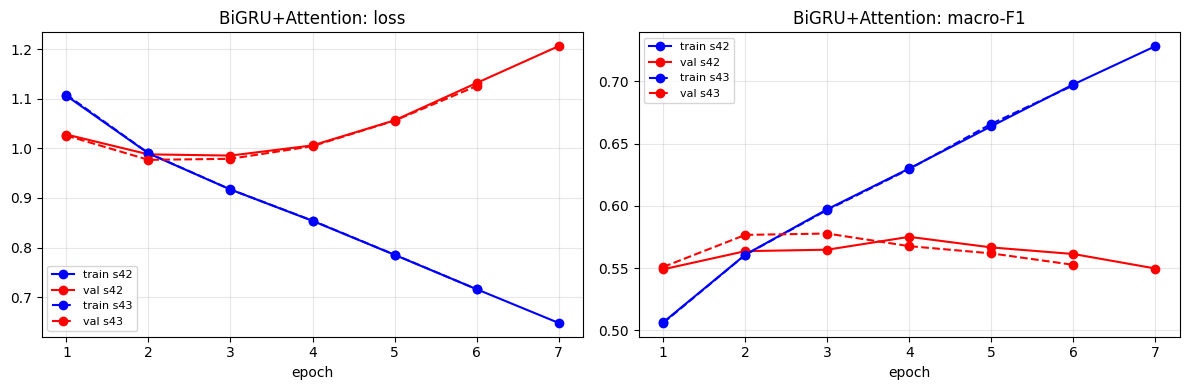

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s in SEEDS:
    ls = '-' if s == SEEDS[0] else '--'; h = HIST[s]
    ax[0].plot(h.epoch, h.train_loss, 'b' + ls, marker='o', label=f'train s{s}'); ax[0].plot(h.epoch, h.val_loss, 'r' + ls, marker='o', label=f'val s{s}')
    ax[1].plot(h.epoch, h.train_f1, 'b' + ls, marker='o', label=f'train s{s}');   ax[1].plot(h.epoch, h.val_f1, 'r' + ls, marker='o', label=f'val s{s}')
for a, t in zip(ax, ['BiGRU+Attention: loss', 'BiGRU+Attention: macro-F1']):
    a.set_title(t); a.set_xlabel('epoch'); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{CKPT_DIR}/baseline_curves.png', dpi=150); plt.show()

## 7. Evaluation on the TEST set (once per model)
Each seed's best checkpoint is scored once; the predictions are cached on Drive and reused. Metrics: accuracy, macro-F1, per-class F1, MAE of the predicted star rating, and the share of adjacent (off by 1 star) and distant (off by 2+ stars) errors; mean ± std (ddof=1) over the 2 seeds.

In [11]:
def get_test_preds(s):
    path = ckpt_path(s)
    cache = f'{CKPT_DIR}/testpred_baseline_s{s}_{int(os.path.getmtime(path))}.npy'
    if os.path.exists(cache): p = np.load(cache)                      # evaluated before -> reuse
    else:
        model = load_base(path); p = base_logits(model, Xte).argmax(1).numpy(); np.save(cache, p); del model; torch.cuda.empty_cache()
    np.save(f'{CKPT_DIR}/final_testpred_baseline_s{s}.npy', p)       # stable name, used by notebook 3
    return p

def compute_metrics(y, p):
    d = np.abs(y - p)
    out = dict(accuracy=accuracy_score(y, p), macro_F1=f1_score(y, p, average='macro'), MAE=d.mean(),
               adjacent_err=(d == 1).mean(), distant_err=(d >= 2).mean())
    for k, v in enumerate(f1_score(y, p, average=None, labels=range(5))): out[f'F1_{k+1}star'] = v
    return out

test_preds = {s: get_test_preds(s) for s in SEEDS}
rows = pd.DataFrame([compute_metrics(yte, test_preds[s]) for s in SEEDS], index=[f'seed {s}' for s in SEEDS])
display(rows.round(4))
summary = rows.agg(['mean', 'std']).apply(lambda c: f'{c["mean"]:.4f} ± {c["std"]:.4f}')
print('\nmean ± std over seeds:'); display(summary.to_frame('BiGRU+Attn'))
rows.to_csv(f'{CKPT_DIR}/baseline_test_metrics.csv')
json.dump(dict(params_M=P_BASE, minutes={str(s): MINS[s] for s in SEEDS}, best_epoch={str(s): float(best_row(HIST[s]).epoch) for s in SEEDS}),
          open(f'{CKPT_DIR}/baseline_info.json', 'w'))
print(f'parameters: {P_BASE:.2f}M | training time per run: {np.mean(list(MINS.values())):.1f} min')

,accuracy,macro_F1,MAE,adjacent_err,distant_err,F1_1star,F1_2star,F1_3star,F1_4star,F1_5star
seed 42,0.5712,0.5678,0.5166,0.3608,0.0680,0.6651,0.4833,0.4101,0.5542,0.7265
seed 43,0.5796,0.5746,0.5092,0.3500,0.0704,0.6692,0.4650,0.4339,0.5477,0.7571



mean ± std over seeds:


,BiGRU+Attn
accuracy,0.5754 ± 0.0059
macro_F1,0.5712 ± 0.0048
MAE,0.5129 ± 0.0052
adjacent_err,0.3554 ± 0.0076
distant_err,0.0692 ± 0.0017
F1_1star,0.6671 ± 0.0029
F1_2star,0.4741 ± 0.0130
F1_3star,0.4220 ± 0.0169
F1_4star,0.5509 ± 0.0046
F1_5star,0.7418 ± 0.0217


parameters: 8.03M | training time per run: 9.7 min


### Normalised confusion matrix and error structure (baseline)

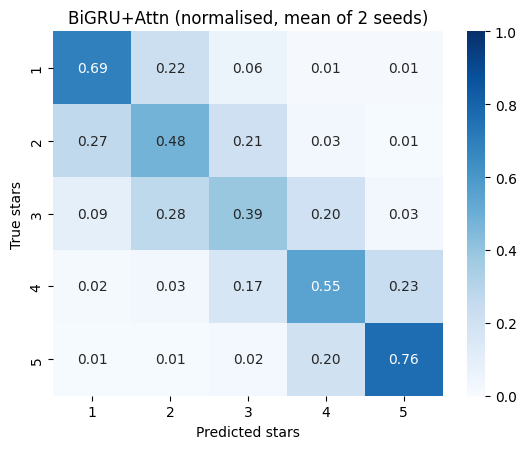

of all errors -> adjacent 83.7%, distant (>=2 stars) 16.3%
4->5: 0.234 | 5->4: 0.198 | 1->5: 0.014 | 5->1: 0.009
lowest per-class F1: 3★ (0.422), 2★ (0.474)


In [12]:
cm = np.mean([confusion_matrix(yte, test_preds[s], normalize='true') for s in SEEDS], axis=0)
fig, a = plt.subplots(figsize=(5.6, 4.6))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=a, xticklabels=range(1, 6), yticklabels=range(1, 6))
a.set_title(f'BiGRU+Attn (normalised, mean of {len(SEEDS)} seeds)'); a.set_xlabel('Predicted stars'); a.set_ylabel('True stars')
plt.tight_layout(); plt.savefig(f'{CKPT_DIR}/baseline_confusion.png', dpi=150); plt.show()

adj, dist = [], []
for s in SEEDS:
    diff = np.abs(yte - test_preds[s]); err = diff > 0
    adj.append((diff[err] == 1).mean()); dist.append((diff[err] >= 2).mean())
print(f'of all errors -> adjacent {np.mean(adj):.1%}, distant (>=2 stars) {np.mean(dist):.1%}')
print(f'4->5: {cm[3,4]:.3f} | 5->4: {cm[4,3]:.3f} | 1->5: {cm[0,4]:.3f} | 5->1: {cm[4,0]:.3f}')
print('lowest per-class F1:', ', '.join(f'{k+1}★ ({rows[f"F1_{k+1}star"].mean():.3f})' for k in np.argsort([rows[f'F1_{k+1}star'].mean() for k in range(5)])[:2]))

### Baseline summary
- **Overfitting.** The validation loss is lowest after about 2–3 epochs and then rises while the training loss keeps falling, so early stopping on validation macro-F1 selected epoch 4 (seed 42) and epoch 3 (seed 43) and the runs stopped after 7 and 6 epochs.
- **Test performance** (mean ± std, 2 seeds): accuracy 0.5754 ± 0.0059, macro-F1 0.5712 ± 0.0048, MAE 0.5129 ± 0.0052; 83.7% of the errors are off by exactly one star, and 6.9% of all reviews are off by two or more stars.
- **Hardest classes:** 3★ (F1 0.422) and 2★ (F1 0.474), the middle ratings, where neighbouring classes are partly subjective.
- **Cost:** 8.03M parameters and about 10 minutes per run.

**Next:** notebook 3 fine-tunes RoBERTa, runs the pooling ablation and compares both models using the predictions and histories saved here.